# Customer Segmentation Using K-Means Clustering

**Oasis Infobyte – Data Analytics Internship**

**Level 1 – Task 2**

## Project Objective

The objective of this project is to segment mall customers based on their annual income and spending behaviour using K-Means clustering.

The analysis will identify customer groups with different spending patterns and provide marketing recommendations based on their characteristics.

The project includes exploratory data analysis, data preprocessing, the Elbow Method, K-Means clustering, cluster visualisation and customer segment interpretation.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv('/content/Mall_Customers.csv')

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Data Inspection and Cleaning

Before applying K-Means clustering, the dataset is examined for missing values, duplicate records, incorrect data types and unusual values.

This step helps determine whether the customer data requires preprocessing before segmentation.

In [14]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Total Missing Values:
0


In [15]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Customer IDs:",
      df["CustomerID"].duplicated().sum())

Duplicate Rows: 0
Duplicate Customer IDs: 0


In [16]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [17]:
print("Descriptive Statistics:")
display(df.describe())

print("\nGender Distribution:")
print(df["Gender"].value_counts())

Descriptive Statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Gender Distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64


In [18]:
print("Invalid Ages:",
      (df["Age"] <= 0).sum())

print("Negative Annual Income:",
      (df["Annual Income (k$)"] < 0).sum())

print("Spending Scores Outside 1–100:",
      (~df["Spending Score (1-100)"].between(1, 100)).sum())

Invalid Ages: 0
Negative Annual Income: 0
Spending Scores Outside 1–100: 0


## Exploratory Data Analysis

Exploratory Data Analysis is performed to understand customer demographics, income distribution and spending behaviour.

The visualisations help identify patterns that may be useful for customer segmentation.

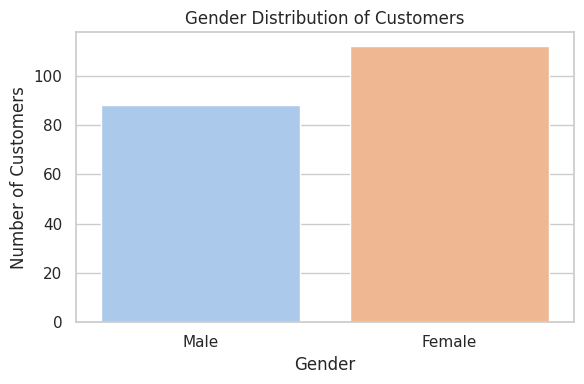

In [19]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Gender",
    hue="Gender",
    palette="pastel",
    legend=False
)

plt.title("Gender Distribution of Customers")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

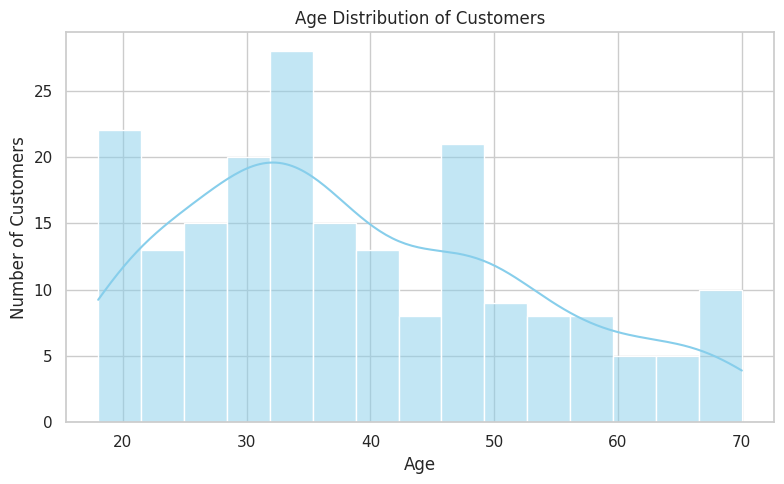

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True,
    color="skyblue"
)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

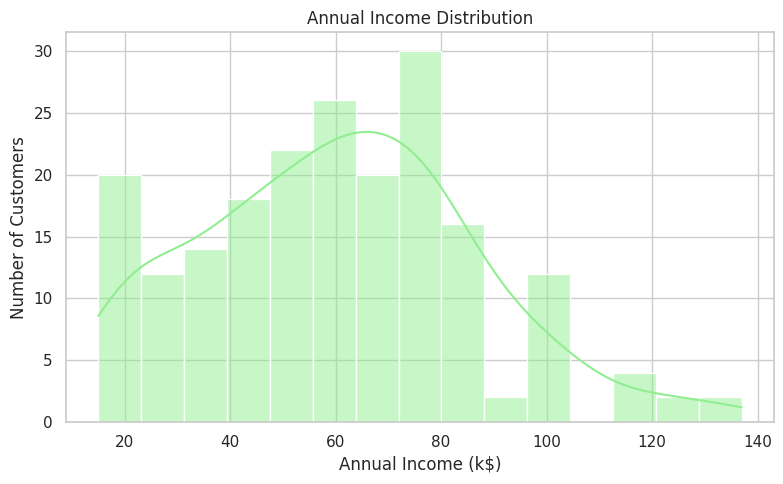

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Annual Income (k$)",
    bins=15,
    kde=True,
    color="lightgreen"
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

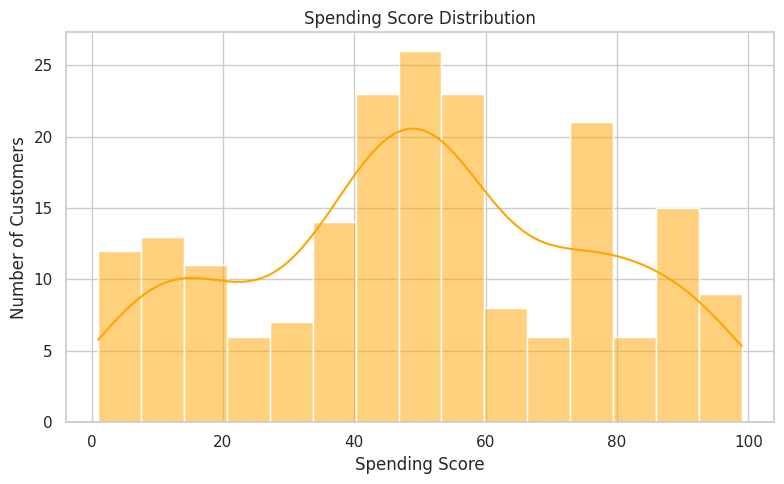

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Spending Score (1-100)",
    bins=15,
    kde=True,
    color="orange"
)

plt.title("Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

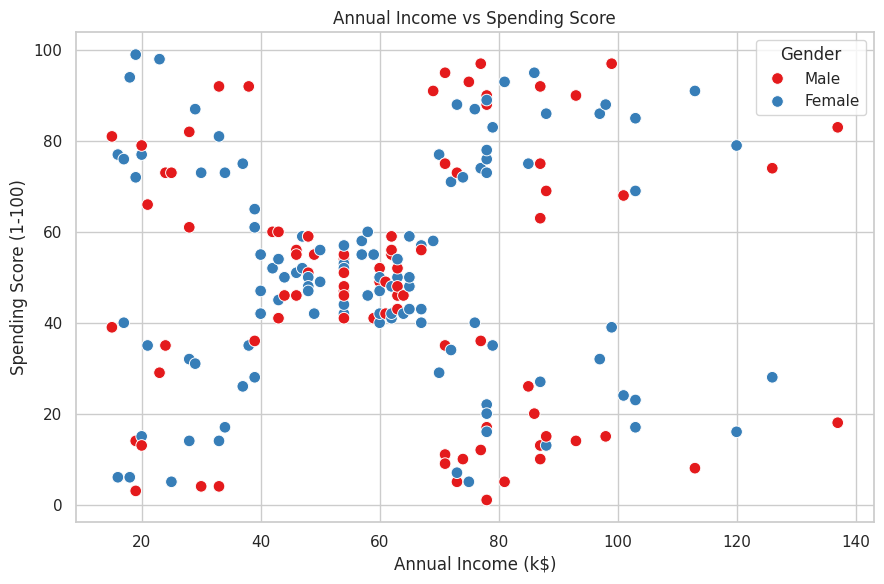

In [23]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    palette="Set1",
    s=70
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

### EDA Observations

The exploratory analysis examines the gender composition, age distribution, annual income and spending scores of 200 mall customers.

The income-versus-spending scatter plot is particularly relevant because these two variables will be used for K-Means clustering.

The visualisations provide an initial understanding of customer differences. The number and characteristics of customer segments will be determined in the clustering stage.

## K-Means Clustering – Elbow Method

The Elbow Method is used to select a suitable number of clusters for K-Means.

It compares the within-cluster sum of squares (WCSS) for different values of K. WCSS measures how closely customers are grouped around their cluster centres.

A bend in the curve can indicate a suitable cluster count, although the choice should also consider the interpretability of the resulting segments.

In [24]:
# Select features for customer segmentation
X = df[[
    "Annual Income (k$)",
    "Spending Score (1-100)"
]].copy()

print("Selected Features:")
display(X.head())

print("Feature Shape:", X.shape)

Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


Feature Shape: (200, 2)


In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardisation completed!")
print("Scaled Data Shape:", X_scaled.shape)

Standardisation completed!
Scaled Data Shape: (200, 2)


In [26]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print("WCSS Values:")
for k, value in enumerate(wcss, start=1):
    print(f"K={k}: {value:.2f}")

WCSS Values:
K=1: 400.00
K=2: 269.69
K=3: 157.70
K=4: 108.92
K=5: 65.57
K=6: 55.06
K=7: 44.86
K=8: 37.23
K=9: 32.39
K=10: 29.98


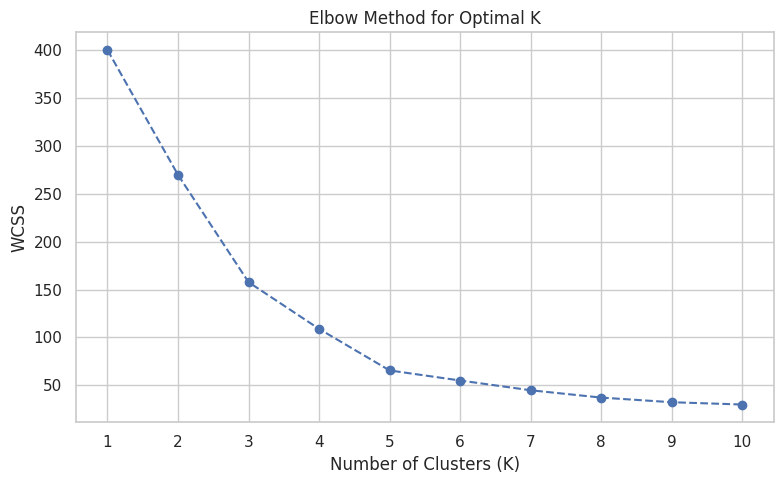

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o",
    linestyle="--"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

### Elbow Method Observation

The Elbow Method was applied to standardised annual income and spending score values.

As the number of clusters increases, WCSS decreases. The aim is to identify a point where the rate of improvement begins to slow.

The selected number of clusters will be used to train the final K-Means model and interpret the resulting customer segments.

## Customer Segmentation Using K-Means Clustering

K-Means clustering is an unsupervised machine learning algorithm that groups customers according to similarities in their characteristics.

In this project, customers are segmented using annual income and spending score. The resulting clusters will help identify different customer spending patterns and support targeted marketing strategies.

In [28]:
from sklearn.cluster import KMeans

# Provisional number of clusters
optimal_k = 5

# Create K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    random_state=42,
    n_init=10
)

# Fit model using scaled data
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

print("\nCustomers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

display(df.head())

K-Means clustering completed!

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


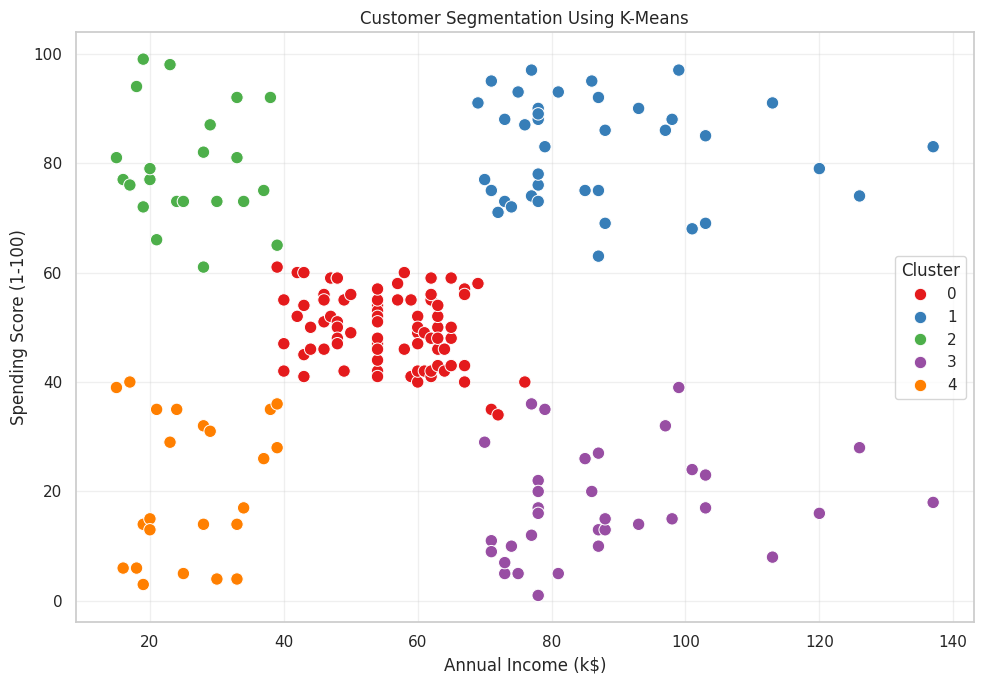

In [29]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=80
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.5547


In [31]:
cluster_summary = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Cluster Summary:")
display(cluster_summary)

Customer Cluster Summary:


,Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


### K-Means Clustering Observations

K-Means clustering was applied to the standardised annual income and spending score features.

The model assigned each customer to a cluster based on similarity to the cluster centres.

A scatter plot was created to visualise the customer segments. The cluster summary provides the number of customers, average age, average annual income and average spending score for each group.

The resulting segments will be interpreted to identify customer profiles and develop suitable marketing recommendations.

## Customer Segment Analysis

After applying K-Means clustering, the customer groups are analysed using their average annual income, spending score and age.

The purpose is to understand the characteristics of each cluster and identify potential marketing strategies for different customer segments.

In [32]:
cluster_analysis = df.groupby("Cluster").agg(
    Total_Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

cluster_analysis["Percentage"] = (
    cluster_analysis["Total_Customers"] / len(df) * 100
).round(2)

display(cluster_analysis)

,Total_Customers,Average_Age,Average_Income,Average_Spending,Percentage
Cluster,,,,,
0,81,42.72,55.30,49.52,40.5
1,39,32.69,86.54,82.13,19.5
2,22,25.27,25.73,79.36,11.0
3,35,41.11,88.20,17.11,17.5
4,23,45.22,26.30,20.91,11.5


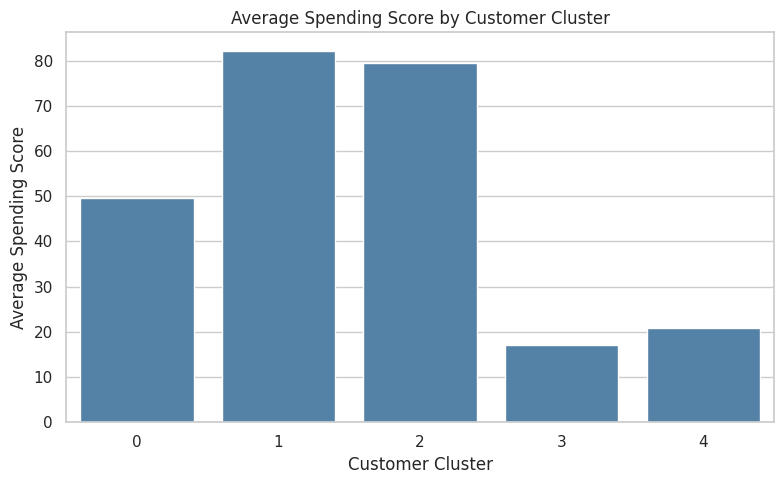

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Cluster",
    y="Spending Score (1-100)",
    estimator="mean",
    errorbar=None,
    color="steelblue"
)

plt.title("Average Spending Score by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending Score")
plt.tight_layout()
plt.show()

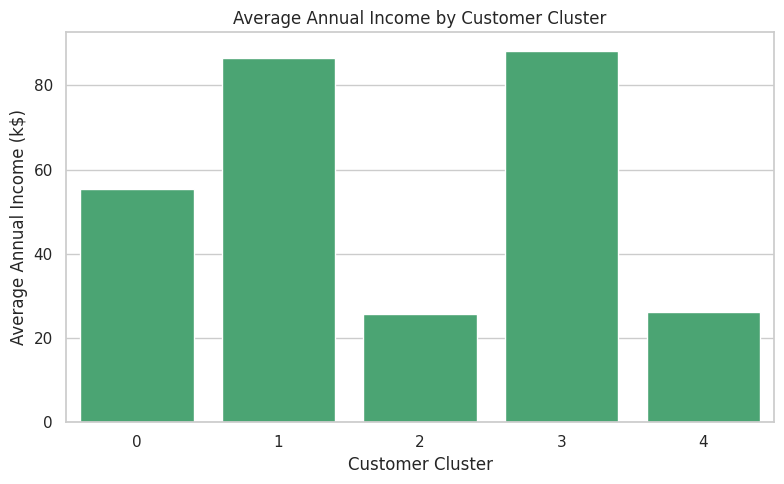

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Cluster",
    y="Annual Income (k$)",
    estimator="mean",
    errorbar=None,
    color="mediumseagreen"
)

plt.title("Average Annual Income by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Annual Income (k$)")
plt.tight_layout()
plt.show()

In [35]:
income_avg = df["Annual Income (k$)"].mean()
spending_avg = df["Spending Score (1-100)"].mean()

def segment_name(row):
    high_income = row["Average_Income"] >= income_avg
    high_spending = row["Average_Spending"] >= spending_avg

    if high_income and high_spending:
        return "High Income - High Spending"
    elif high_income and not high_spending:
        return "High Income - Low Spending"
    elif not high_income and high_spending:
        return "Low Income - High Spending"
    else:
        return "Low Income - Low Spending"

cluster_analysis["Segment_Name"] = cluster_analysis.apply(
    segment_name, axis=1
)

display(cluster_analysis)

,Total_Customers,Average_Age,Average_Income,Average_Spending,Percentage,Segment_Name
Cluster,,,,,,
0,81,42.72,55.30,49.52,40.5,Low Income - Low Spending
1,39,32.69,86.54,82.13,19.5,High Income - High Spending
2,22,25.27,25.73,79.36,11.0,Low Income - High Spending
3,35,41.11,88.20,17.11,17.5,High Income - Low Spending
4,23,45.22,26.30,20.91,11.5,Low Income - Low Spending


## Business Recommendations

The customer segmentation results can help businesses develop more targeted marketing strategies.

**High Income – High Spending:** These customers may be suitable for premium product recommendations, loyalty programmes and exclusive offers.

**High Income – Low Spending:** Businesses could investigate whether their product range meets these customers' preferences and test personalised promotions.

**Low Income – High Spending:** Value-focused loyalty rewards, discounts and affordable product bundles may appeal to these customers.

**Low Income – Low Spending:** Businesses could explore budget-friendly products and occasional promotional campaigns.

These recommendations are hypotheses based on income and spending scores. Additional customer behaviour data would be needed to evaluate their effectiveness.

In [36]:
# Add descriptive segment names to each customer
df["Segment_Name"] = df["Cluster"].map(
    cluster_analysis["Segment_Name"]
)

# Export customer segmentation results
df.to_csv(
    "Mall_Customers_Segmented.csv",
    index=False
)

print("Segmented dataset saved successfully!")

Segmented dataset saved successfully!


## Results and Discussion

The K-Means clustering model groups mall customers based on annual income and spending score.

The analysis compares the size, average age, annual income and spending behaviour of each cluster. These characteristics help identify differences between customer groups and support potential marketing strategies.

The cluster labels are numerical identifiers rather than rankings. The interpretation of each segment depends on its observed characteristics.

In [37]:
print("CUSTOMER SEGMENTATION RESULTS")
print("-" * 40)

print("Total Customers:", len(df))
print("Number of Clusters:", df["Cluster"].nunique())

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

print("\nSilhouette Score:")
print(round(silhouette_score(X_scaled, df["Cluster"]), 4))

print("\nCustomer Segment Summary:")
display(cluster_analysis)

CUSTOMER SEGMENTATION RESULTS
----------------------------------------
Total Customers: 200
Number of Clusters: 5

Cluster Distribution:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Silhouette Score:
0.5547

Customer Segment Summary:


,Total_Customers,Average_Age,Average_Income,Average_Spending,Percentage,Segment_Name
Cluster,,,,,,
0,81,42.72,55.30,49.52,40.5,Low Income - Low Spending
1,39,32.69,86.54,82.13,19.5,High Income - High Spending
2,22,25.27,25.73,79.36,11.0,Low Income - High Spending
3,35,41.11,88.20,17.11,17.5,High Income - Low Spending
4,23,45.22,26.30,20.91,11.5,Low Income - Low Spending


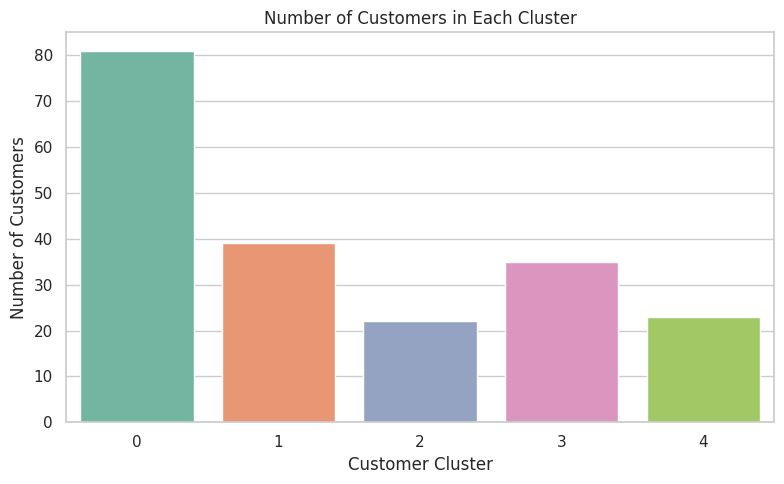

In [38]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Cluster",
    hue="Cluster",
    palette="Set2",
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## Conclusion

This project explored customer segmentation using the Mall Customer Segmentation dataset from Kaggle, containing 200 customer records.

Exploratory Data Analysis was conducted to examine customer age, gender, annual income and spending score. K-Means clustering was then applied to standardised annual income and spending score values.

The resulting clusters provide a way to distinguish customers with different income and spending characteristics. Cluster profiles were examined using average income, spending score, age and customer counts.

These findings can support the development of targeted marketing strategies, such as premium product promotions, loyalty programmes and value-focused offers. However, the effectiveness of these strategies would need to be tested using additional customer behaviour data.

The project demonstrates how unsupervised machine learning can be used to explore customer differences and support business decision-making.

## Project Limitations

1. The dataset contains only 200 customers, which limits how broadly the findings can be generalised.
2. K-Means clustering uses only annual income and spending score, so other factors influencing customer behaviour are not included in the clustering model.
3. Spending Score is a numerical indicator rather than a direct measurement of total customer expenditure.
4. The dataset does not contain transaction dates or purchase histories, so RFM analysis cannot be performed.
5. K-Means requires the number of clusters to be selected and may produce different results depending on feature selection and preprocessing.
6. The proposed marketing recommendations are based on observed customer characteristics and have not been tested for effectiveness.

## Future Scope

Future improvements could include additional customer characteristics, purchase histories, transaction frequency and customer preferences.

Other clustering algorithms, such as hierarchical clustering and DBSCAN, could also be compared with K-Means to evaluate alternative segmentation approaches.